### ASTR 3300/5300: Astrostatistics
***N. Pol***
___

# Homework 7
### Due: Wednesday, Nov. 18 at 11.59pm CT
---

## Problem 1

This is a regression problem. Many of the parts require minor variations of code to switch to new techniques, but otherwise using a similar workflow. 

Note of warning: the data I have provided have associated uncertainties, `yerr`. `sklearn` and `astroML` have different formats for using uncertainties; in `sklearn` fitting you can provide `sample_weight=1/yerr**2`, while in `astroML` fitting you can directly provide `y_error=yerr`.

1. Read in `hw7_data_1.npy`. The dataset should consist of $500$ samples. The first two columns are the two data features, `X`. The third column is the target labels, `y`, and the final column are the heteroscedastic uncertainties on the labels, `yerr`. Make a 2-panel scatter plot of the labels versus each feature.


2. Use multivariate linear regression on this data with its uncertainties (`astroML` rather than plain `sklearn` is the better option here). Print the best-fit intercept and slopes for the features. Make a prediction `Xgrid` over $50$ values from the min to the max value of each feature, and plot the best-fit model on a duplicate of the $2$-panel plot from (1); does this look like a good description of the data?


3. Make a new two-dimensional prediction meshgrid `Xgrid` over the $2$-D feature space, use your best-fit model to predict the labels, and make a $3$-D interactive plot showing the data and your best-fit over the entire space. You may find the following code useful.

In [34]:
%matplotlib widget

In [35]:
import numpy as np
import matplotlib.pyplot as plt

In [36]:
data = np.load("/Users/jhorna/astrostats_ttu_fall26/coursework/homeworks/hw_data/hw7_data_1.npy")

print(data.shape)
print(data[:5])

(500, 4)
[[ 7.8948247   2.63234381 80.4253773   1.87575433]
 [ 0.52366744  0.51621304 47.10411881  2.91421645]
 [ 4.36807264  4.49797669 36.40116352  1.85647292]
 [ 0.90201939  5.22076883 30.15237219  1.49796527]
 [ 9.78903126  9.89811355 20.0020663   1.02998777]]


In [37]:
X = data[:, :2]
y = data[:, 2]
yerr = data[:, 3]

print(X.shape, y.shape, yerr.shape)

(500, 2) (500,) (500,)


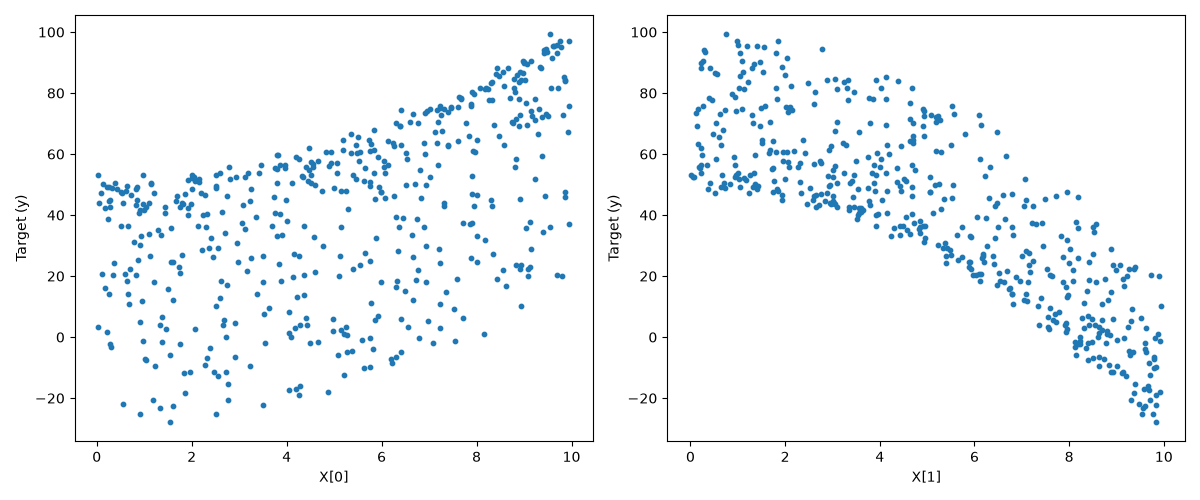

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X[:, 0], y, s=10)
ax[0].set_xlabel("X[0]")
ax[0].set_ylabel("Target (y)")

ax[1].scatter(X[:, 1], y, s=10)
ax[1].set_xlabel("X[1]")
ax[1].set_ylabel("Target (y)")

plt.tight_layout()
plt.show()

In [39]:
from astroML.linear_model import LinearRegression

model = LinearRegression()
model.fit(X, y, y_error=yerr)

print("Best-fit coefficients:", model.coef_)

Best-fit coefficients: [57.10102323  4.94873016 -8.30023407]


In [40]:
x0 = np.linspace(X[:, 0].min(), X[:, 0].max(), 50)
x1 = np.linspace(X[:, 1].min(), X[:, 1].max(), 50)

Xgrid = np.column_stack((x0, x1))
y_pred = model.predict(Xgrid)

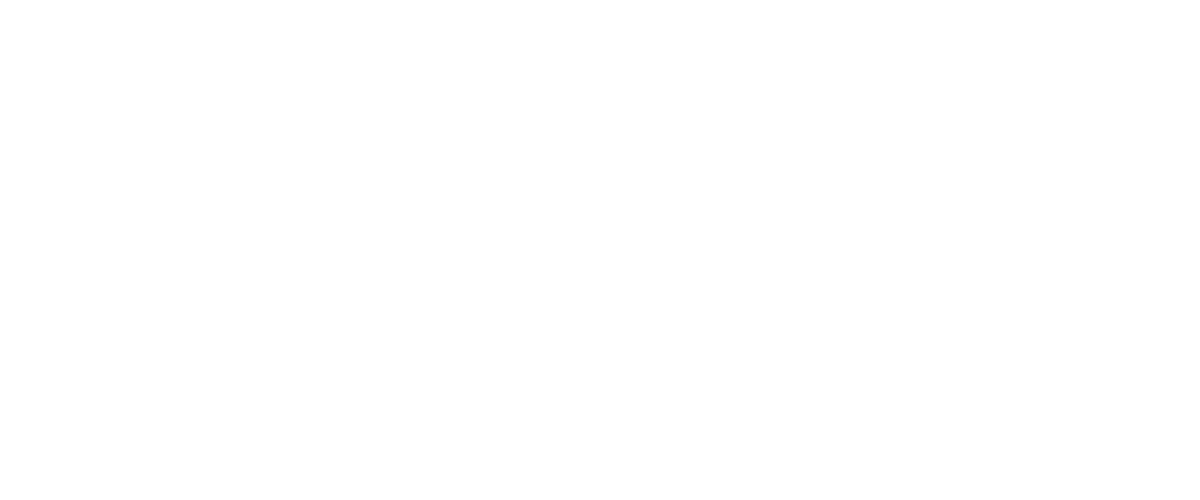

In [41]:
Xgrid0 = np.column_stack((x0, np.full(50, X[:, 1].mean())))
Xgrid1 = np.column_stack((np.full(50, X[:, 0].mean()), x1))

y_pred0 = model.predict(Xgrid0)
y_pred1 = model.predict(Xgrid1)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X[:, 0], y, s=10, alpha=0.5)
ax[0].plot(x0, y_pred0, color='red')
ax[0].set_xlabel("X[0]")
ax[0].set_ylabel("Target (y)")

ax[1].scatter(X[:, 1], y, s=10, alpha=0.5)
ax[1].plot(x1, y_pred1, color='red')
ax[1].set_xlabel("X[1]")
ax[1].set_ylabel("Target (y)")

plt.tight_layout()
plt.show()

The linear model shows the general trends, but it does not fit all the data well. A more complex model may give better results.

In [42]:
x0_grid = np.linspace(X[:, 0].min(), X[:, 0].max(), 50)
x1_grid = np.linspace(X[:, 1].min(), X[:, 1].max(), 50)

xx, yy = np.meshgrid(x0_grid, x1_grid)

Xgrid = np.column_stack((xx.ravel(), yy.ravel()))

z_pred = model.predict(Xgrid).reshape(xx.shape)

In [43]:
# Makes the plot interactive. 
# You can pan the image.

### always do this line at the start 
### of an interactive plotting cell

fig = plt.figure(figsize=(8, 8))

ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k',
        zorder=15, linestyle='none',
        marker='o', alpha=0.5)

ax.scatter(xx.flatten(), yy.flatten(), z_pred.flatten(),
           facecolor=(0, 0, 0), s=20,
           edgecolor='#70b3f0')
ax.set_xlabel('X[0]', fontsize=12)
ax.set_ylabel('X[1]', fontsize=12)
ax.set_zlabel('Target', fontsize=12)

ax.view_init(elev=28, azim=120)

4. Sticking with a linear model, now attempt a `GridSearchCV` procedure on the data to find the best `Ridge` regression hyper-parameters. Use the following `param_grid`:
```
ridge_params = {'alpha': [0.05,0.1,0.2,0.5,1.0], 'solver': ['svd', 'lsqr']}
```
What are the `best_params_` and the `best_score_` from this? Fit the data with the best options, and visualize interactively. Try `RidgeCV` also; what cross-validated `alpha_` does it return, and does this agree with `GridSeachCV`? *(Hint: remember to revert to inline matplotlib when you're done each time you make an interactive plot.)*


5. Now model the data using Gaussian process regression and the default kernel. Check what the fit looks like with and with and without uncertainties accounted for. *(Hint: GPR in `sklearn` takes an `alpha` parameter equal to `(yerr/y)**2`.)*


6. Let's look finally at polynomial fitting. Fit a $4$th degree polynomial to the data. Print the best-fit regression coefficients, predict on the 2D meshgrid, and visualize interactively as before. How does this look compared to the linear model and GPR models?


7. Sticking with polynomial fitting, let's find the optimal hyper-parameters through cross-validation. 
- Using `sklearn.model_selection.train_test_split`, first do a train-test split with a `test_size` of $20\%$. Then split out $20\%$ of the training set itself as a cross-validation set (leaving a somewhat smaller set to use for training). Note that you'll need to simultaneously split out `yerr` as well by just providing this as another array to `train_test_split`.
- Compute the training and cross-validation rms errors (and from those, the BIC values) as a function of polynomial degree from $1$ to $10$ inclusive. Plot the rms errors and BIC values as a function of the polynomial degree. 
- Choose the optimal polynomial degree, and train on all training data from the first `train_test_split` operation. Predict the labels of the held-out test set, and finally compute the testing rms error.

In [44]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import GridSearchCV

ridge_params = {'alpha': [0.05, 0.1, 0.2, 0.5, 1.0],
                'solver': ['svd', 'lsqr']}

grid = GridSearchCV(Ridge(), ridge_params, cv=5)

grid.fit(X, y, sample_weight=1/yerr**2)

print("Best parameters:", grid.best_params_)
print("Best score:", grid.best_score_)

Best parameters: {'alpha': 1.0, 'solver': 'svd'}
Best score: 0.9210232503685034


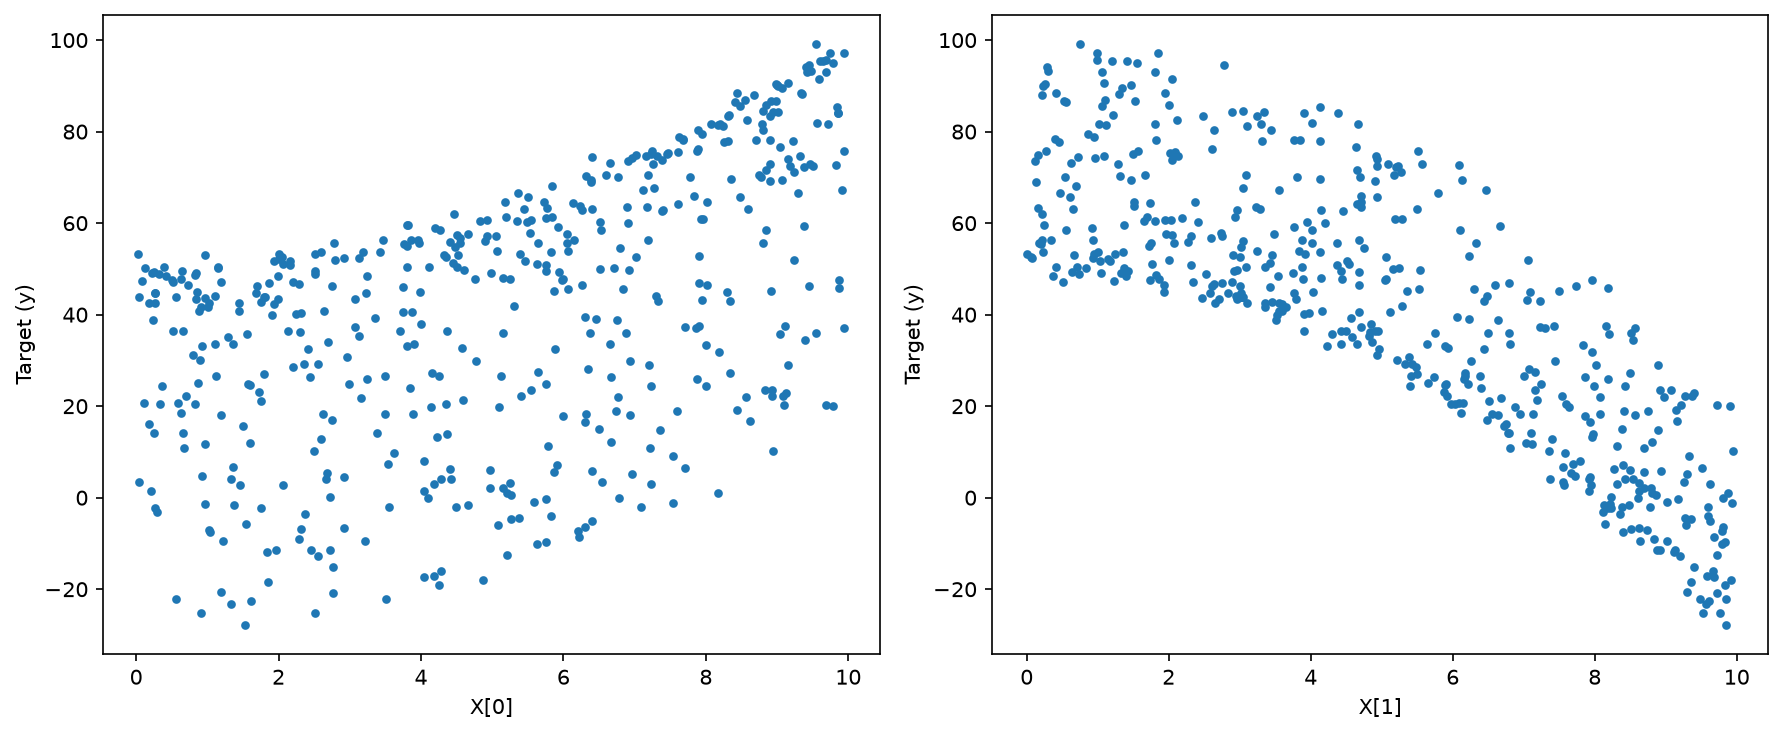

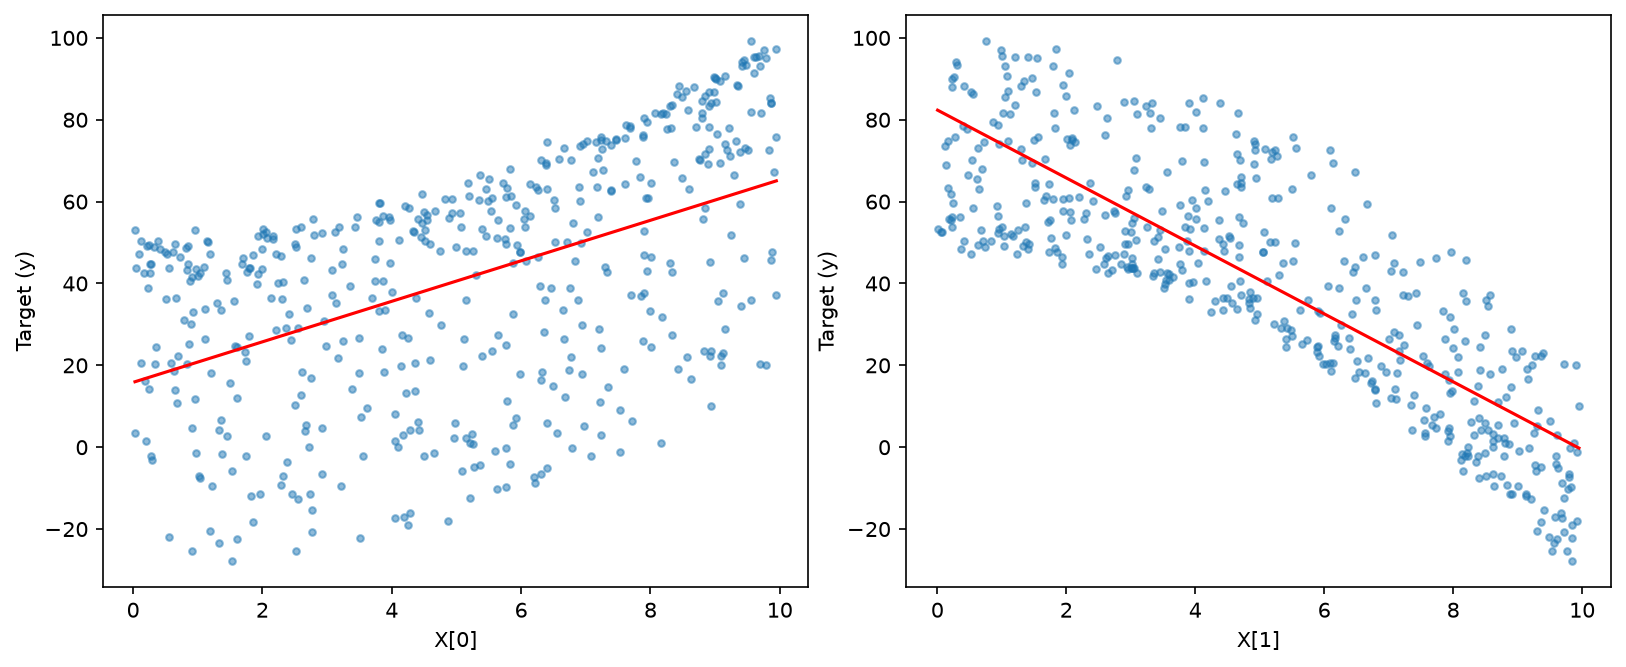

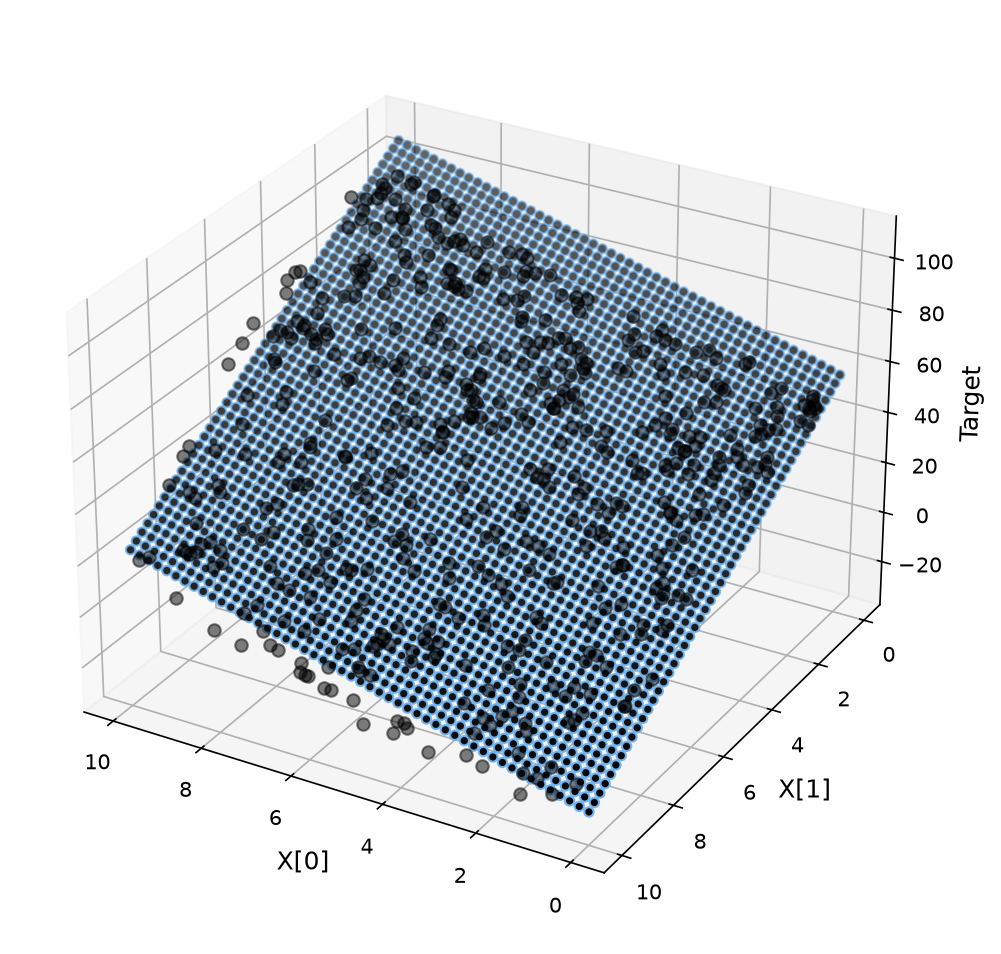

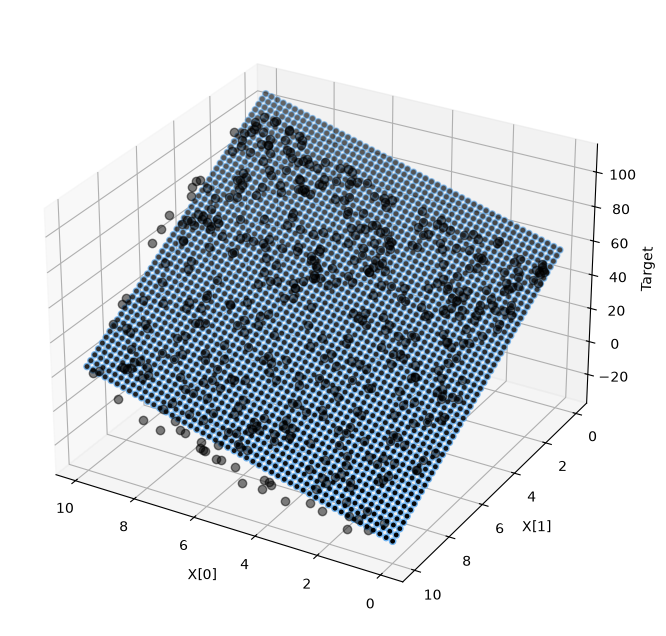

In [45]:
ridge_model = grid.best_estimator_

z_ridge = ridge_model.predict(Xgrid).reshape(xx.shape)

%matplotlib inline

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k',
        zorder=15, linestyle='none',
        marker='o', alpha=0.5)

ax.scatter(xx.flatten(), yy.flatten(), z_ridge.flatten(),
           facecolor=(0, 0, 0), s=20,
           edgecolor='#70b3f0')

ax.set_xlabel('X[0]')
ax.set_ylabel('X[1]')
ax.set_zlabel('Target')

ax.view_init(elev=28, azim=120)
plt.show()

In [46]:
ridge_cv = RidgeCV(alphas=[0.05, 0.1, 0.2, 0.5, 1.0], cv=5)

ridge_cv.fit(X, y, sample_weight=1/yerr**2)

print("RidgeCV alpha:", ridge_cv.alpha_)

RidgeCV alpha: 1.0


Both GridSearchCV and RidgeCV selected alpha = 1.0, so their results agree.

In [47]:
from sklearn.gaussian_process import GaussianProcessRegressor

gpr1 = GaussianProcessRegressor()
gpr1.fit(X, y)

gpr2 = GaussianProcessRegressor(alpha=(yerr/y)**2)
gpr2.fit(X, y)

print("GPR without uncertainties:", gpr1.kernel_)
print("GPR with uncertainties:", gpr2.kernel_)

GPR without uncertainties: 50.1**2 * RBF(length_scale=1e-05)
GPR with uncertainties: 50.2**2 * RBF(length_scale=1e-05)


/Users/jhorna/miniconda3/envs/astr5300/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/Users/jhorna/miniconda3/envs/astr5300/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


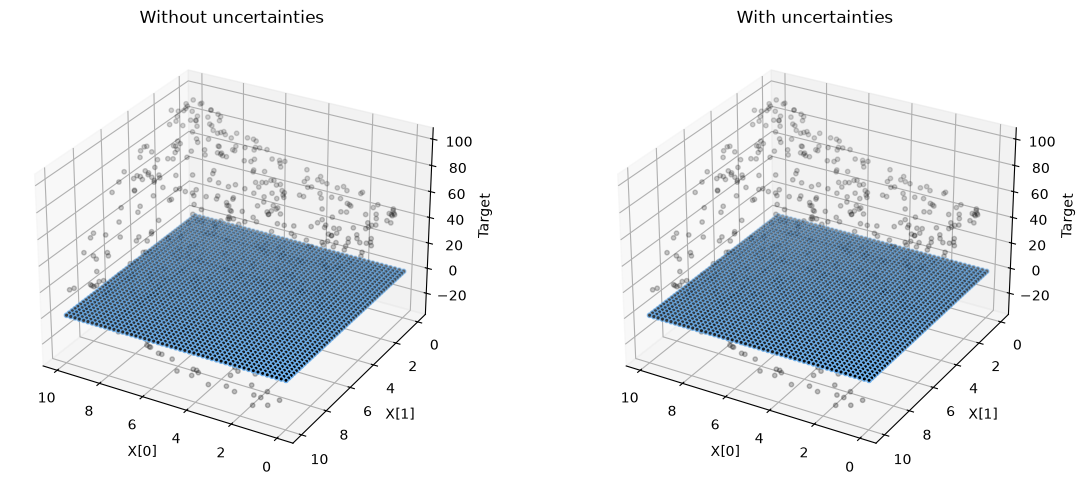

In [48]:
z_gpr1 = gpr1.predict(Xgrid).reshape(xx.shape)
z_gpr2 = gpr2.predict(Xgrid).reshape(xx.shape)

%matplotlib inline

fig = plt.figure(figsize=(12, 5))

for i, (z, title) in enumerate([
    (z_gpr1, "Without uncertainties"),
    (z_gpr2, "With uncertainties")
]):
    ax = fig.add_subplot(1, 2, i+1, projection='3d')

    ax.scatter(X[:, 0], X[:, 1], y, color='k', s=10, alpha=0.5)
    ax.scatter(xx.flatten(), yy.flatten(), z.flatten(),
               facecolor=(0, 0, 0), s=10, edgecolor='#70b3f0')

    ax.set_xlabel('X[0]')
    ax.set_ylabel('X[1]')
    ax.set_zlabel('Target')
    ax.set_title(title)
    ax.view_init(elev=28, azim=120)

plt.tight_layout()
plt.show()

Both GPR models give almost flat predictions and do not fit the data well. Including uncertainties makes very little visible difference.

In [49]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=4)

X_poly = poly.fit_transform(X)

poly_model = LinearRegression(fit_intercept=False)
poly_model.fit(X_poly, y, sample_weight=1/yerr**2)

print("Best-fit coefficients:", poly_model.coef_)

Best-fit coefficients: [ 4.99887582e+01  5.54313398e-01 -2.07866484e-01  2.86536907e-01
  2.93842379e-03 -7.82230112e-01  2.47603263e-02  2.45748271e-02
 -2.22233559e-02  9.68417971e-03 -9.95958746e-04 -1.12284370e-03
 -1.14462222e-03  2.10142159e-03 -1.08539159e-03]


In [50]:
Xgrid_poly = poly.transform(Xgrid)

z_poly = poly_model.predict(Xgrid_poly).reshape(xx.shape)

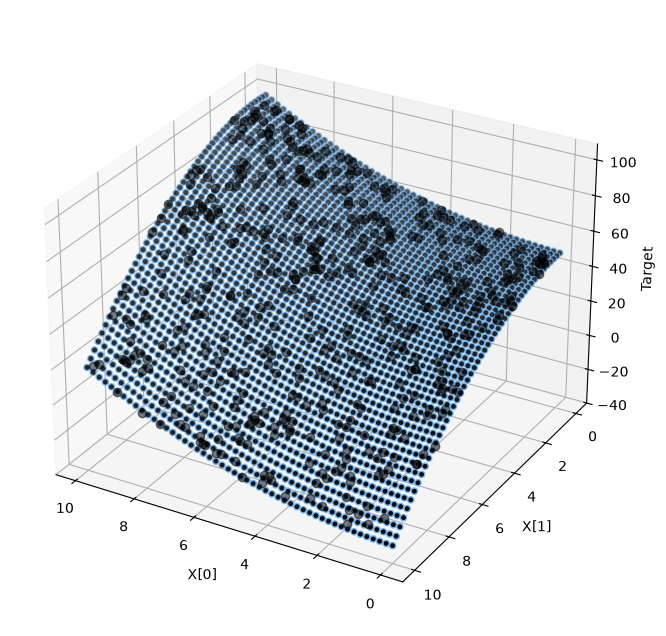

In [51]:
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(X[:, 0], X[:, 1], y, color='k',
        zorder=15, linestyle='none',
        marker='o', alpha=0.5)

ax.scatter(xx.flatten(), yy.flatten(), z_poly.flatten(),
           facecolor=(0, 0, 0), s=20,
           edgecolor='#70b3f0')

ax.set_xlabel('X[0]')
ax.set_ylabel('X[1]')
ax.set_zlabel('Target')

ax.view_init(elev=28, azim=120)

plt.show()

The fourth-degree polynomial fits the data better than the linear and GPR models because it captures the curved patterns in the data.

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test, err_train, err_test = train_test_split(
    X, y, yerr, test_size=0.2, random_state=42
)

X_fit, X_val, y_fit, y_val, err_fit, err_val = train_test_split(
    X_train, y_train, err_train, test_size=0.2, random_state=42
)

print("Training:", len(X_fit))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 320
Validation: 80
Testing: 100


In [53]:
from sklearn.metrics import mean_squared_error

train_rms = []
val_rms = []
bic_values = []

for degree in range(1, 11):
    poly = PolynomialFeatures(degree=degree)

    X_fit_poly = poly.fit_transform(X_fit)
    X_val_poly = poly.transform(X_val)

    reg = LinearRegression(fit_intercept=False)
    reg.fit(X_fit_poly, y_fit, sample_weight=1/err_fit**2)

    pred_train = reg.predict(X_fit_poly)
    pred_val = reg.predict(X_val_poly)

    train_rms.append(np.sqrt(mean_squared_error(y_fit, pred_train)))
    val_rms.append(np.sqrt(mean_squared_error(y_val, pred_val)))

    n = len(y_fit)
    k = X_fit_poly.shape[1]
    rss = np.sum((y_fit - pred_train)**2)

    bic = n * np.log(rss/n) + k * np.log(n)
    bic_values.append(bic)

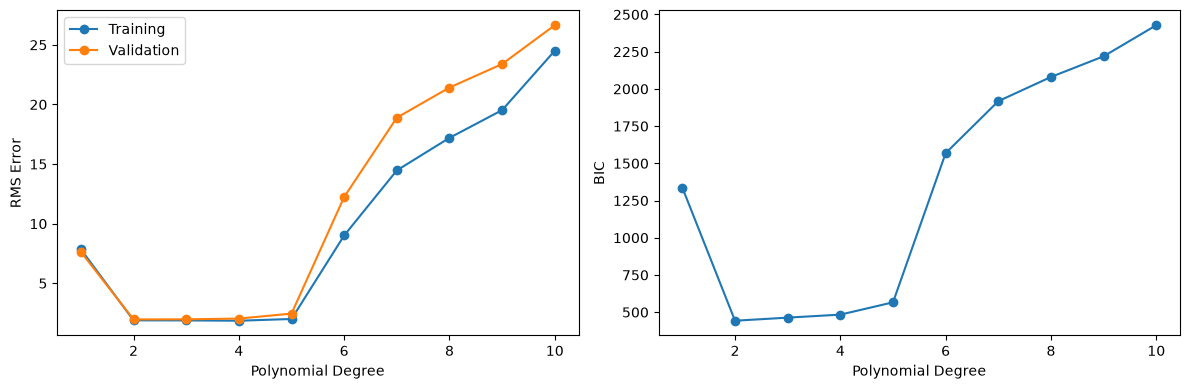

In [54]:
degrees = np.arange(1, 11)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(degrees, train_rms, 'o-', label='Training')
ax[0].plot(degrees, val_rms, 'o-', label='Validation')
ax[0].set_xlabel('Polynomial Degree')
ax[0].set_ylabel('RMS Error')
ax[0].legend()

ax[1].plot(degrees, bic_values, 'o-')
ax[1].set_xlabel('Polynomial Degree')
ax[1].set_ylabel('BIC')

plt.tight_layout()
plt.show()

In [55]:
best_degree = degrees[np.argmin(val_rms)]
print("Best degree:", best_degree)

poly_best = PolynomialFeatures(degree=best_degree)

X_train_best = poly_best.fit_transform(X_train)
X_test_best = poly_best.transform(X_test)

best_model = LinearRegression(fit_intercept=False)
best_model.fit(X_train_best, y_train, sample_weight=1/err_train**2)

y_test_pred = best_model.predict(X_test_best)

test_rms = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Testing RMS:", test_rms)

Best degree: 2
Testing RMS: 1.9492137379315908


The second-degree polynomial gives the lowest validation error, with a testing RMS of about 1.95. Higher-degree models perform worse.

## Problem 2


1. Use the following code snippet to read in SDSS galaxy color data.
<!--```
from astroML.datasets import fetch_sdss_galaxy_colors
data = fetch_sdss_galaxy_colors()
```-->

`data = np.load('../hw_data/hw7_data_2.npy')`

This is a structured numpy array. Find and print all of the column names. Using the data, create arrays of $(u-g)$, $(g-r)$, $(r-i)$, and $(i-z)$ colors. Also create arrays of redshift and the spectral class. How many regular galaxies and how many quasars are in this sample?


2. Make a scatter plot of $(u-g)$ versus $(g-r)$, color coding by galaxy or quasar class. The plot should include appropriate axis labels and a legend. Set `xlim` between -0.5 and 2.5, and `ylim` between -0.5 and 1.5.


3. Stack all colors and the redshift into a data matrix, $X$. Create a target label array that has $0$ for a regular galaxy and $1$ for a quasar. Perform a train-test split, taking $20\%$ of the data for testing.


4. Create a compact `for` loop that iterates over the fitting of a Gaussian Naive Bayes classification algorithm to successively more features of the data. Within the loop, compute and plot an ROC curve. The end result should be a plot showing ROC curves for GNB classification with more and more features of the data, with appropriate axis labels and a legend. Use `xlim` between 0 and 0.01. Which feature seems to make the classification trivially easy? *Note: `predict_proba` returns an array with as many columns as classes. You've labeled quasars as $1$, so for the ROC curve you must make sure to access the relevant quasar probability-- you can find this by accessing the **classes_** attribute of the estimator.*


5. Repeat (4) for Quadratic Discriminant Analysis. 


6. Let's try classification with GMM Bayes. Restrict the training and testing to be just on the $4$ colors. Iterate now over number of components in the GMM Bayes fit up to $10$, plotting ROC curves for all, and find the number of components that gives the best performance.


7. Repeat (6) for $K$-nearest neighbor classification, looping over number of neighbors between 5 and 100 in steps of 10. Find the number that gives the best performance. 


8. Repeat (6) for Decision Tree classification, looping over the maximum tree depth between 1 and 10. Find the number that gives the best performance. 


9. Finally, plot the ROC curves for GNB, QDA, and the best-performing GMMBayes, KNN, and DT classification algorithms, all using just the 4 colors. What is the overall best-performing classifier? 


10. Make a 2-panel plot, showing in the left panel the color-coded training data in $(u-g)$ versus $(g-r)$ (similar to item 2 above), and in the right panel the same features of the testing data color coded by their predicted class from the tuned best-performing classifier. 

In [56]:
data2 = np.load("/Users/jhorna/astrostats_ttu_fall26/coursework/homeworks/hw_data/hw7_data_2.npy")

print(data2.shape)
print(data2[:5])
print(data2.dtype.names)

(50000,)
[(19.46392, 18.89363, 18.85225, 18.8241 , 18.53599, 'QSO', 2.312959  , 1.925222e-04)
 (18.33262, 16.29118, 15.3018 , 14.81997, 14.45467, 'GALAXY', 0.05187586, 1.396275e-05)
 (18.85941, 17.01412, 15.97252, 15.51533, 15.11948, 'GALAXY', 0.09769295, 1.805014e-05)
 (19.23528, 17.96798, 17.30418, 16.94234, 16.67086, 'GALAXY', 0.04988256, 8.922353e-06)
 (19.29932, 17.40602, 16.44753, 16.00617, 15.61255, 'GALAXY', 0.04429447, 1.164774e-05)]
('u', 'g', 'r', 'i', 'z', 'specClass', 'redshift', 'redshift_err')


In [57]:
u_g = data2['u'] - data2['g']
g_r = data2['g'] - data2['r']
r_i = data2['r'] - data2['i']
i_z = data2['i'] - data2['z']

redshift = data2['redshift']
specClass = data2['specClass']

print("Galaxies:", np.sum(specClass == 'GALAXY'))
print("Quasars:", np.sum(specClass == 'QSO'))

Galaxies: 42808
Quasars: 7192


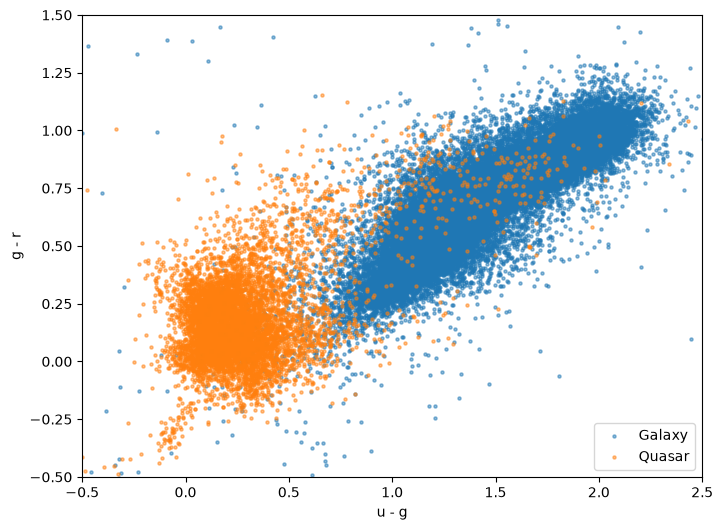

In [58]:
plt.figure(figsize=(8, 6))

plt.scatter(u_g[specClass == 'GALAXY'], g_r[specClass == 'GALAXY'],
            s=5, alpha=0.5, label='Galaxy')

plt.scatter(u_g[specClass == 'QSO'], g_r[specClass == 'QSO'],
            s=5, alpha=0.5, label='Quasar')

plt.xlabel('u - g')
plt.ylabel('g - r')
plt.xlim(-0.5, 2.5)
plt.ylim(-0.5, 1.5)
plt.legend()
plt.show()

In [59]:
from sklearn.model_selection import train_test_split

X = np.column_stack((u_g, g_r, r_i, i_z, redshift))
y = (specClass == 'QSO').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(40000, 5) (10000, 5)
(40000,) (10000,)


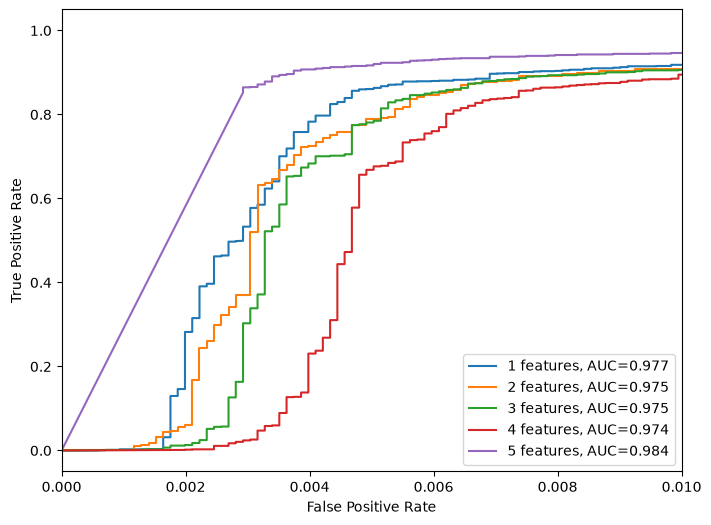

In [60]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

for n in range(1, 6):
    gnb = GaussianNB()
    gnb.fit(X_train[:, :n], y_train)

    y_prob = gnb.predict_proba(X_test[:, :n])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{n} features, AUC={roc_auc:.3f}')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 0.01)
plt.legend()
plt.show()

Adding redshift improves the classification. Using all five features gives the best AUC of 0.984.

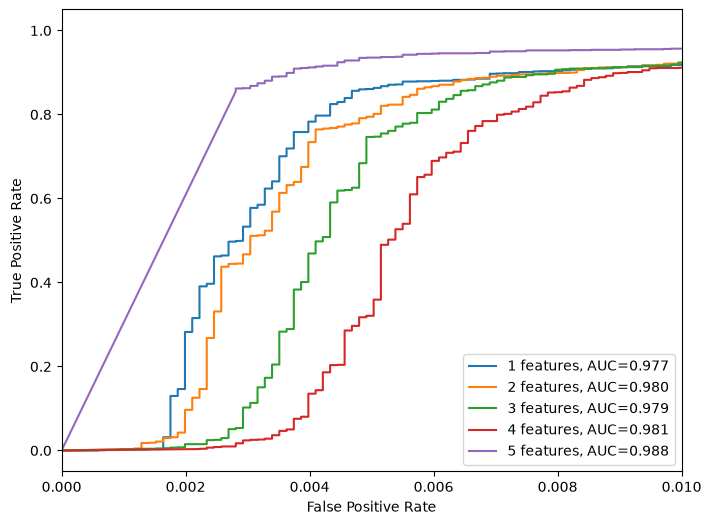

In [61]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

plt.figure(figsize=(8, 6))

for n in range(1, 6):
    qda = QuadraticDiscriminantAnalysis()
    qda.fit(X_train[:, :n], y_train)

    y_prob = qda.predict_proba(X_test[:, :n])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{n} features, AUC={roc_auc:.3f}')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 0.01)
plt.legend()
plt.show()

QDA gives slightly better results than GNB. Using all five features gives the highest AUC of 0.988.

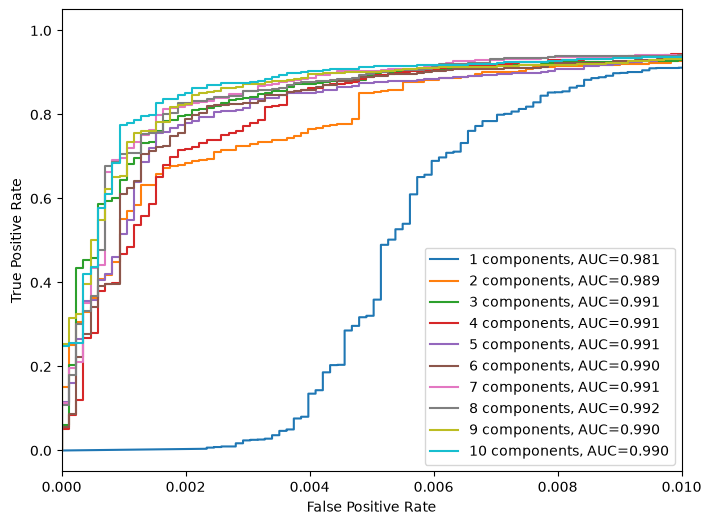

Best number of components: 8
Best AUC: 0.9915187735368562


In [62]:
from astroML.classification import GMMBayes

plt.figure(figsize=(8, 6))

best_auc = 0
best_n = 0

for n in range(1, 11):
    gmm = GMMBayes(n_components=n, random_state=42)
    gmm.fit(X_train[:, :4], y_train)

    y_prob = gmm.predict_proba(X_test[:, :4])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{n} components, AUC={roc_auc:.3f}')

    if roc_auc > best_auc:
        best_auc = roc_auc
        best_n = n

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 0.01)
plt.legend()
plt.show()

print("Best number of components:", best_n)
print("Best AUC:", best_auc)

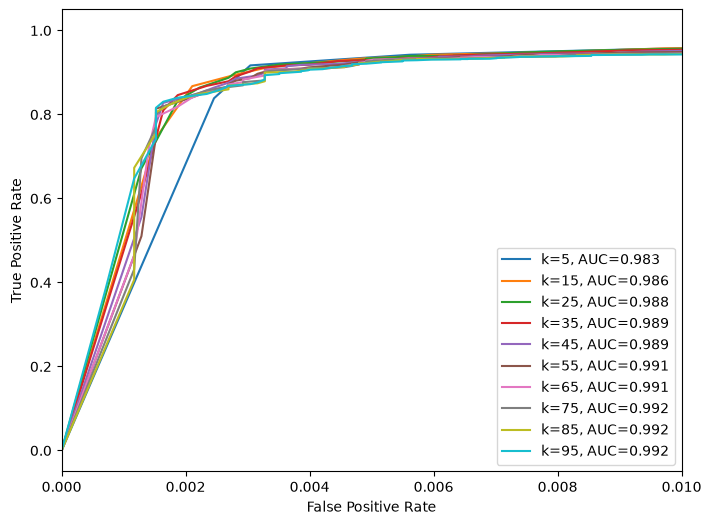

Best number of neighbors: 95
Best AUC: 0.9922689706419516


In [63]:
from sklearn.neighbors import KNeighborsClassifier

plt.figure(figsize=(8, 6))

best_auc = 0
best_k = 0

for k in range(5, 101, 10):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train[:, :4], y_train)

    y_prob = knn.predict_proba(X_test[:, :4])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'k={k}, AUC={roc_auc:.3f}')

    if roc_auc > best_auc:
        best_auc = roc_auc
        best_k = k

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 0.01)
plt.legend()
plt.show()

print("Best number of neighbors:", best_k)
print("Best AUC:", best_auc)

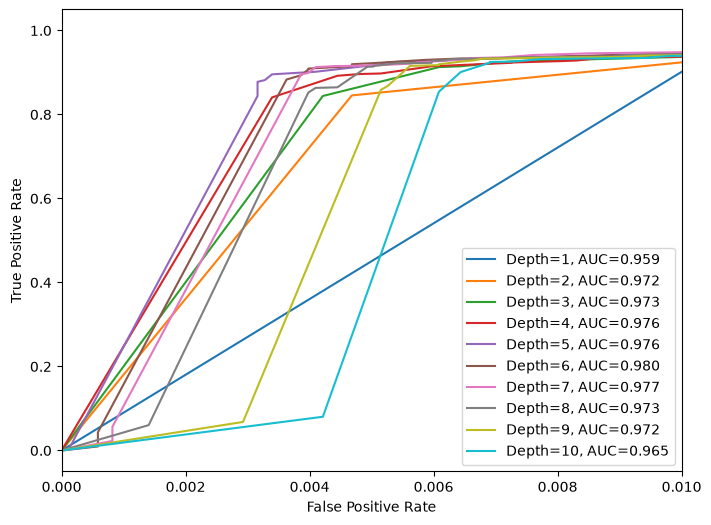

Best tree depth: 6
Best AUC: 0.9803963227198831


In [64]:
from sklearn.tree import DecisionTreeClassifier

plt.figure(figsize=(8, 6))

best_auc = 0
best_depth = 0

for depth in range(1, 11):
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42)
    dt.fit(X_train[:, :4], y_train)

    y_prob = dt.predict_proba(X_test[:, :4])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'Depth={depth}, AUC={roc_auc:.3f}')

    if roc_auc > best_auc:
        best_auc = roc_auc
        best_depth = depth

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 0.01)
plt.legend()
plt.show()

print("Best tree depth:", best_depth)
print("Best AUC:", best_auc)

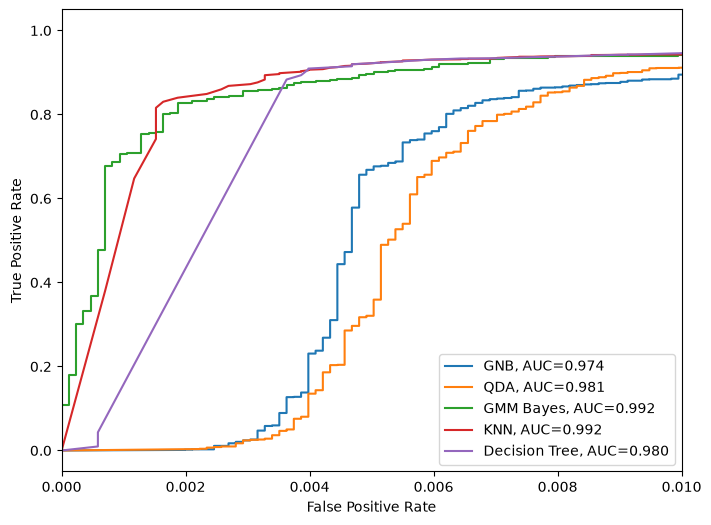

In [65]:
models = {
    'GNB': GaussianNB(),
    'QDA': QuadraticDiscriminantAnalysis(),
    'GMM Bayes': GMMBayes(n_components=8, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=95),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42)
}

plt.figure(figsize=(8, 6))

for name, clf in models.items():
    clf.fit(X_train[:, :4], y_train)
    y_prob = clf.predict_proba(X_test[:, :4])[:, 1]

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{name}, AUC={roc_auc:.3f}')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim(0, 0.01)
plt.legend()
plt.show()

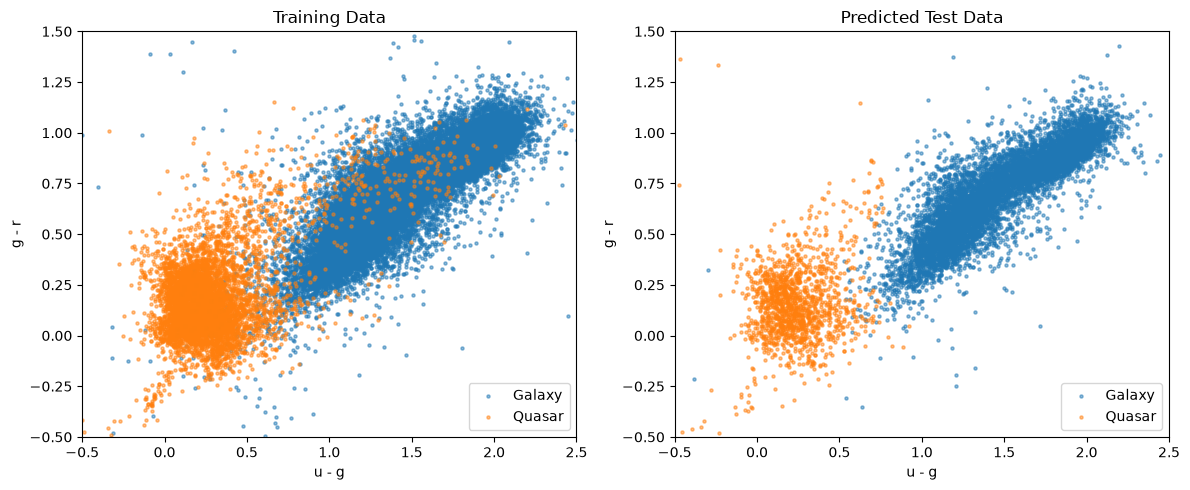

In [66]:
knn = KNeighborsClassifier(n_neighbors=95)
knn.fit(X_train[:, :4], y_train)

y_pred = knn.predict(X_test[:, :4])

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

for label, name in [(0, 'Galaxy'), (1, 'Quasar')]:
    ax[0].scatter(X_train[y_train == label, 0],
                  X_train[y_train == label, 1],
                  s=5, alpha=0.5, label=name)

    ax[1].scatter(X_test[y_pred == label, 0],
                  X_test[y_pred == label, 1],
                  s=5, alpha=0.5, label=name)

for a in ax:
    a.set_xlabel('u - g')
    a.set_ylabel('g - r')
    a.set_xlim(-0.5, 2.5)
    a.set_ylim(-0.5, 1.5)
    a.legend()

ax[0].set_title('Training Data')
ax[1].set_title('Predicted Test Data')

plt.tight_layout()
plt.show()

The KNN model does a good job of identifying galaxies and quasars. The predicted results look similar to the training data.